## 1. Motivación

Una entidad financiera (un banco) funciona, en esencia, sobre una idea sencilla: sus clientes realizan **depósitos** que pueden retirar, en principio, con libertad.

Por otro lado, el banco no deja ese dinero parado: lo **invierte** (en préstamos, bonos o proyectos), y esas inversiones suelen necesitar tiempo para dar un beneficio sustancial. Esta combinación, depósitos que se pueden retirar en cualquier momento e inversiones que tardan en dar fruto, se conoce como **transformación de vencimientos** y es la función principal de la mayoría de entidades bancarias.

Ahora bien, esto implica que el banco **no tiene todo el dinero de sus clientes en caja**, porque gran parte está invertido. Imaginemos que una parte muy significativa de los clientes decide retirar su dinero en el mismo instante: el banco puede tener problemas de liquidez para atender todas las peticiones. Por esta razón, un banco aparentemente sano puede tener serias dificultades, o incluso quebrar, si sus clientes sienten pánico ante la incertidumbre y creen que los demás van a retirar. A este fenómeno se le conoce como **corrida bancaria** (*bank run*).

Este suceso ha ocurrido de forma significativa a lo largo de la historia y, en consecuencia, la regulación al respecto se ha endurecido notablemente. Un caso relativamente reciente es el de **Silicon Valley Bank** en marzo de 2023: sus clientes retiraron decenas de miles de millones de dólares en cuestión de días, como si siguieran el manual que acabamos de resumir, empujados por el temor de que los demás retirasen antes que ellos.

Lo importante de este contexto es darnos cuenta de que **la decisión de cada cliente depende de la que toman los demás**, y de la incertidumbre que genera que varios agentes interactúen en una especie de "juego". Es, por tanto, un escenario ideal para estudiarlo con la rama de las matemáticas conocida como **teoría de juegos**.

> **Pregunta que guía el trabajo:** ¿puede un banco sano y solvente quebrar tan solo por las expectativas de sus clientes? Y, si es así, ¿qué herramientas tienen las entidades bancarias y los reguladores para evitarlo?






## 2. El modelo

Con este contexto podemos plantear un modelo inicial para entender hacia dónde nos dirigimos. Construiremos una versión simple, inspirada en el modelo de **Diamond y Dybvig (1983)**, un artículo estándar en el estudio de las corridas bancarias.

**Jugadores.** Dos depositantes, A y B.

**Cronología:**

1. Cada depositante ingresa una unidad monetaria en el banco (euros, por convención), es decir, hay 2 euros en el banco.
2. El banco invierte todo el capital (2 euros) en un proyecto a largo plazo.
3. Cada depositante decide, **a la vez** y sin conocer la decisión del otro, entre dos acciones: **Esperar** (mantener el dinero hasta el final) o **Retirar** (sacar el dinero ya).
4. Se pagan los resultados.

**Rendimiento del proyecto:**

- Si se espera hasta la finalización, el proyecto rinde un 50 %: se recuperan los 2 euros invertidos y se gana 1 adicional, es decir, el capital asciende a **3 euros**.
- Si hay que liquidarlo antes de tiempo, solo se recupera **1 euro** en total: se pierde el 50 % de la inversión.

**Pago a quien retira antes de tiempo.** Suponiendo que el banco no cuenta con más liquidez, promete devolver 1 euro a quien retire antes, **por orden de llegada**: el primero cobra y, al agotarse esa liquidez, el banco no puede pagar al siguiente.

### Supuestos simplificadores

- Solo hay **2 depositantes**.
- La decisión se toma **a la vez**: no se puede cooperar ni decidir en función de lo que haga el otro.
- Los depositantes son **neutrales al riesgo**: les interesa el pago medio y no tienen en cuenta la inseguridad.
- Si ambos retiran a la vez, el orden de llegada es aleatorio, así que cada uno tiene probabilidad 1/2 de cobrar primero.
- Todo el dinero depositado se invierte y solo se recupera terminando o liquidando el proyecto, lo que limita la liquidez del banco.

Estos supuestos son teóricos y los iremos modificando ("relajando") para acercarnos a la realidad.

## 3. Pagos del juego

Para que el juego pueda desarrollarse necesitamos tres ingredientes:

1. **Jugadores**
2. **Acciones**
3. **Pagos**

Un **pago** es lo que recibe cada jugador según lo que hagan **ambos**. Habitualmente en teoría de juegos se representa con una **matriz de pagos**, donde cada casilla muestra *(pago de A, pago de B)*:

$$
\begin{array}{c|cc}
 & \text{B espera} & \text{B retira} \\
\hline
\text{A espera} & (1.5,\ 1.5) & (0,\ 1) \\
\text{A retira} & (1,\ 0) & (0.5,\ 0.5)
\end{array}
$$

**Cómo se calcula cada casilla:**

- **Ambos esperan:** el proyecto rinde 3, que se reparten a partes iguales: 1.5 cada uno.
- **Uno retira y el otro espera:** para pagar al que retira hay que liquidar el proyecto en el instante, lo que proporciona 1 euro que va íntegro al que retira. El que espera se queda sin nada.
- **Ambos retiran:** en caja solo hay 1 euro y se han prometido 2. Cada uno tiene un 50 % de probabilidad de cobrar 1 y un 50 % de no cobrar nada, es decir, **0.5 de media**.

Lo mejor para ambos es **esperar** (1.5 cada uno), pero esperar es arriesgado: si el otro retira, quien espera pierde toda la inversión.

### 3.1 La matriz de pagos en Python

Expresamos la matriz en código. Las acciones se ordenan como 0 = Esperar,  1 = Retirar. `A` contiene los pagos del jugador A (filas = acción de A, columnas = acción de B). Como el juego es simétrico, los pagos de B son la **traspuesta**: B está en la misma situación que A con los papeles cambiados.



In [6]:
import numpy as np
r = 1.5
A = np.array([[r, 0], [1, 0.5]])
B = A.T
print("Pagos de A: \n", A)
print("Pagos de B: \n", B)

Pagos de A: 
 [[1.5 0. ]
 [1.  0.5]]
Pagos de B: 
 [[1.5 1. ]
 [0.  0.5]]


Hasta aquí hemos logrado tener un contexto general del trabajo y traducir el problema a una matriz de pagos con la que se puede hacer calculos. En el siguiente apartado veremos cuáles son las **predicciones del juego** suponiendo que ambos depositantes son racionales, es decir, que buscan maximizar su pago.

## 4. Posibles frentes y equilibrio de Nash

Llamamos **mejor respuesta** de un jugador, a la acción que este puede realizar y que le brinda un mayor pago *suponiendo que la acción del otro depositante es conocida*

Para el depositante A:

$$
\begin{array}{c|cc|c}
\textbf{Si B hace...} & \textbf{A espera} & \textbf{A retira} & \textbf{Mejor respuesta de A} \\
\hline
\textbf{Esperar} & 1.5 & 1 & \textbf{Esperar} \\
\textbf{Retirar} & 0 & 0.5 & \textbf{Retirar}
\end{array}
$$

Por tanto, la mejor respuesta **depende intrinsecamente** de lo que haga el otro depositante, esto quiere decir, que no existe lo que llamamos una estrategia **dominante** (Una estrategia dominante es aquella que siempre es superior independientemente de la elección del rival).
Por simetría, exactamente lo mismo se puede decir de B.

Un **equilibrio de Nash** es una combinación de series de acciones en la que **ambos jugadores aplican su mejor estrategia/respuesta simultaneamente**, de este modo, nadie puede mejorar cambiando solo su decisión.

Esto ocurre en las siguientes casillas de la tabla:

$$
\begin{array}{c|cc}
 & \text{B espera} & \text{B retira} \\
\hline
\text{A espera} & \boxed{(1.5,\ 1.5)} & (0,\ 1) \\
\text{A retira} & (1,\ 0) & \boxed{(0.5,\ 0.5)}
\end{array}
$$


En estrategias puras hay **2 equilibrios de Nash** y son los siguientes:

1. **(Esperar,Esperar):** En esta situación ambos confian (actitud cooperante) y por consiguiente cobran 1.5, dejandolo en un mejor resultado para **ambos**
2. **(Retirar,Retirar):** En esta situación se ilustra el **pánico**, ante una posición de no fiabilidad, los individuos no se muestran cooperantes y ambos cobran 0.5.

También existe un **equilibrio en estrategias mixtas**: cada depositante espera con probabilidad 0.5 y retira con probabilidad 0.5. La celda siguiente busca únicamente los equilibrios en **estrategias puras**, que son los dos resultados deterministas mostrados en la tabla.

Se puede observar claramente que el segundo es peor para ambos y podriamos preguntarnos por que no escoger la primera opción siempre, aquí es donde entra la dinámica de juego e incertidumbre, **el equilibrio menos beneficioso tambien es estable**.

Un juego de este tipo sigue una estructura de **juego de coordinación** en el que el resultado depende enteramente de las expectativas de los participantes, es decir, en lo que el uno espera del otro y el banco es meramente un **medio** para dicha practica.

In [7]:
acciones = ["Esperar", "Retirar"]

for i in range(2):          
    for j in range(2):      
        a_se_desvia = A[1 - i, j] > A[i, j]
        b_se_desvia = B[i, 1 - j] > B[i, j]
        if not a_se_desvia and not b_se_desvia:
            print(f"Equilibrio de Nash puro: (A {acciones[i]}, B {acciones[j]})")

Equilibrio de Nash puro: (A Esperar, B Esperar)
Equilibrio de Nash puro: (A Retirar, B Retirar)


## 5. Verificación formal de los equilibrios

En el apartado anterior verificamos los equilibrios puros mediante un bucle lógico iterando sobre las decisiones. Sin embargo, para escalar este tipo de problemas en ciencia de datos y teoría de juegos, es recomendable utilizar librerías matemáticas especializadas. 

Vamos a utilizar `nashpy`, una librería estándar en Python para calcular equilibrios en juegos de suma no nula. Instalación `!pip install nashpy` en tu entorno.

Pasaremos las matrices `A` y `B` que definimos en el Paso 3 para ver qué predicciones matemáticas nos arroja la librería.

In [8]:
import nashpy as nash

juego_banco = nash.Game(A, B)

equilibrios = list(juego_banco.support_enumeration())

print("Juego definido en Nashpy:\n", juego_banco)
print("\nEquilibrios de Nash encontrados:")

acciones = ["Esperar", "Retirar"]
for i, eq in enumerate(equilibrios):
    print(f"\nEquilibrio {i+1}:")
    print(f" - Probabilidades de A (Esperar, Retirar): {eq[0]}")
    print(f" - Probabilidades de B (Esperar, Retirar): {eq[1]}")

Juego definido en Nashpy:
 Bi matrix game with payoff matrices:

Row player:
[[1.5 0. ]
 [1.  0.5]]

Column player:
[[1.5 1. ]
 [0.  0.5]]

Equilibrios de Nash encontrados:

Equilibrio 1:
 - Probabilidades de A (Esperar, Retirar): [1. 0.]
 - Probabilidades de B (Esperar, Retirar): [1. 0.]

Equilibrio 2:
 - Probabilidades de A (Esperar, Retirar): [0. 1.]
 - Probabilidades de B (Esperar, Retirar): [0. 1.]

Equilibrio 3:
 - Probabilidades de A (Esperar, Retirar): [0.5 0.5]
 - Probabilidades de B (Esperar, Retirar): [0.5 0.5]


Al ejecutar la celda superior, observamos que la librería nos devuelve **3 resultados**:
1. `[1. 0.]` para ambos: Es decir, 100% de probabilidad de Esperar. Corresponde al equilibrio puro **(Esperar, Esperar)**.
2. `[0. 1.]` para ambos: Es decir, 100% de probabilidad de Retirar. Corresponde al equilibrio puro de pánico **(Retirar, Retirar)**.
3. `[0.5 0.5]` para ambos. Este es el **Equilibrio en Estrategias Mixtas**. 

Como vemos esta libreria nos devulve lo que parece ser **un tercer equilibrio**, esto se debe a que nosotros solo planteamos un juego de Nash en estrategias puras y el sistema genera automáticamente un **equilibrio en estrategias mixtas**, a continuación vamos a ver este concepto, su implicación, en este caso, financiera y la forma en la que esta modalidad de juego genera otro equilibrio.

## 6. Equilibrios de Nash en estrategias mixtas

En la vida real rara vez los participantes conocen con certeza las decisiones que tomará el otro depositante, es aquí donde la incertidumbre aparece.

### 6.1 Definición formal y principio de indiferencia

En teoría de juegos, un **equilibrio de Nash en estrategias mixtas** ($\sigma$) ocurre cuando los participantes asignan una probabilidad a cada una de las acciones a tomar.

 En terminos mas rigurosos, se aplica un distribución de probabilidad sobre el espacio de acción de estrategias puras, asignando sendas probabilidades escogidas, a cada acción posible (entiendase como un mapeado de ponderaciones sobre un jugador $i$).

 El concepto fundamental de la existencia de este equilibrio es el **principio de indiferencia**.

El **teorema de Nash** garantiza que todo juego finito tiene al menos un equilibrio (posiblemente en estrategias mixtas). El **principio de indiferencia** es una propiedad que cumple cualquiera de esos equilibrios: en un equilibrio en estrategias mixtas, si un usuario decide asignar una probabilidad estrictamente mayor a 0 a varias estrategias puras, **todas esas estrategias deben reportarle exactamente la misma utilidad esperada**.

La razón de este supuesto/teorema será discutida mas extensamente mas adelante pero podríamos preguntarmos simplemente el **¿Por qué?**

Para demostrarlo podemos usar lógica sencilla, supongamos que si la estrategia pura "Esperar" le diera al jugador A una utilidad esperada de 2, y "Retirar" le diera 1, el jugador A, siendo racional, jamás jugaría "Retirar". Asignaría probabilidad 1 a "Esperar" y 0 a "Retirar" (volviendo a ser un equilibrio puro).

Por lo tanto, para que un jugador esté dispuesto a aleatorizar sus decisiones, *debe ser matemáticamente indiferente entre ellas*.

Pero esto puede entrar en conflicto con el hecho de que durante el juego el usuario asigna unas probabilidades, que se sobreentiende que ha calculado de alguna forma para asignarlos de forma óptima, pero de alguna forma, este teorema troncal, nos infiere a mantenernos aparentemente "inconscientes" a pesar de saber cierta información y de esta forma asignar las probabilidades de forma indiferente a las mismas, abordaremos esta aparente contradicción en el apartado 7.

### 6.2 Desarrollo del sistema de ecuaciones en estrategias mixtas



Para formalizar el juego vamos a definir un espacio de acciones/creencias:
* Sea $p$ la probabilidad (o la creencia que tiene A) de que el jugador B elija **Esperar**.
* Sea $(1-p)$ la probabilidad de que el jugador B elija **Retirar**.

Nuestros jugadores, en este caso el A, son **agentes racionales** y por tanto seguirán lo que conocemos como **Teoría de utilidad esperada de Von Neumann-Morgenstern** ($\mathbb{E}[U]$) Calculamos la esperanza matemática de los pagos de A para cada una de sus estrategias puras, dadas las probabilidades de B:

1. **Esperanza de A si juega "Esperar" (E):**
   $$\mathbb{E}[U_A(E, \sigma_B)] = p \cdot U_A(E,E) + (1-p) \cdot U_A(E,R)$$
   Sustituyendo con los valores de nuestra matriz:
   $$\mathbb{E}[U_A(E, \sigma_B)] = p(1.5) + (1-p)(0) = \mathbf{1.5p}$$

2. **Esperanza de A si juega "Retirar" (R):**
   $$\mathbb{E}[U_A(R, \sigma_B)] = p \cdot U_A(R,E) + (1-p) \cdot U_A(R,R)$$
   Sustituyendo los valores:
   $$\mathbb{E}[U_A(R, \sigma_B)] = p(1) + (1-p)(0.5) = p + 0.5 - 0.5p = \mathbf{0.5p + 0.5}$$



3. **Aplicamos el principio de indiferencia.** Para que A esté dispuesto a aleatorizar, ambas acciones deben darle la misma utilidad esperada:
   $$1.5p = 0.5p + 0.5 \quad\Longrightarrow\quad p = 0.5$$

   Por simetría, lo mismo se cumple para B. Esto confirma el tercer equilibrio que nos devolvió `nashpy`: **cada depositante espera con probabilidad 0.5**.

### 6.3 Lectura financiera: un umbral de creencia

El valor $p = 0.5$ no es solo "la probabilidad del equilibrio mixto". Tiene una lectura mucho más útil: **es un umbral de confianza**.

- Si A cree que B esperará con probabilidad **mayor** que 0.5, entonces $1.5p > 0.5p + 0.5$ y su mejor respuesta es **Esperar**.
- Si cree que la probabilidad es **menor** que 0.5, su mejor respuesta es **Retirar**.
- Exactamente en 0.5, le da igual.

Es decir, cada depositante compara su **creencia** sobre los demás con un umbral. Esta idea de "decido según si mi creencia supera un umbral" es la semilla de los **juegos globales**, que veremos en el notebook 2.

### 6.4 Generalización: ¿de qué depende el umbral?

Hasta ahora el rendimiento estaba fijado (cada depositante cobra $r = 1.5$ si ambos esperan). Dejemos $r$ libre y repitamos la cuenta:

$$\mathbb{E}[U_A(E)] = r\,p \qquad\qquad \mathbb{E}[U_A(R)] = p + 0.5(1-p) = 0.5p + 0.5$$

Igualando:

$$r\,p = 0.5p + 0.5 \quad\Longrightarrow\quad \boxed{p^*(r) = \frac{0.5}{r - 0.5}}$$

**Interpretación:**

- **Cuanto más rentable es esperar** ($r$ grande), **menor es** $p^*$: basta con poca confianza en el otro para que compense quedarse. Un banco con inversiones muy rentables es más difícil de "tumbar" por pánico.
- **Si $r \le 1$**, entonces $p^* \ge 1$: ninguna creencia hace preferible esperar. Retirar se vuelve una **estrategia dominante** y el único equilibrio es la corrida. Tiene sentido: si esperar no paga más que retirar, nadie arriesga.
- Para $r > 1$ conviven los tres equilibrios (dos puros y uno mixto).

Comprobémoslo numéricamente: calculamos $p^*$ con la fórmula y con `nashpy` para varios valores de $r$.

In [9]:
def matriz_pagos(r):
    # Pagos del depositante A (filas: A espera/retira; columnas: B espera/retira)
    return np.array([[r, 0], [1, 0.5]])

def umbral_creencia(r):
    # Probabilidad p* que hace a A indiferente entre esperar y retirar
    return 0.5 / (r - 0.5)

print(f"{'r':>5} | {'p* fórmula':>10} | {'p* nashpy':>10}")
print("-" * 33)
for r in [1.2, 1.5, 2.0, 3.0]:
    A_r = matriz_pagos(r)
    juego = nash.Game(A_r, A_r.T)
    # Nos quedamos con el equilibrio estrictamente mixto (probabilidad de esperar entre 0 y 1)
    mixto = [eq for eq in juego.support_enumeration() if 0 < eq[1][0] < 1][0]
    print(f"{r:>5} | {umbral_creencia(r):>10.4f} | {mixto[1][0]:>10.4f}")

    r | p* fórmula |  p* nashpy
---------------------------------
  1.2 |     0.7143 |     0.7143
  1.5 |     0.5000 |     0.5000
  2.0 |     0.3333 |     0.3333
  3.0 |     0.2000 |     0.2000


Las dos columnas coinciden: la fórmula derivada a mano es la misma que calcula la librería.

Para fijar la intuición, dibujamos las dos utilidades esperadas de A en función de su creencia $p$. El punto donde se cortan es el umbral $p^*$.

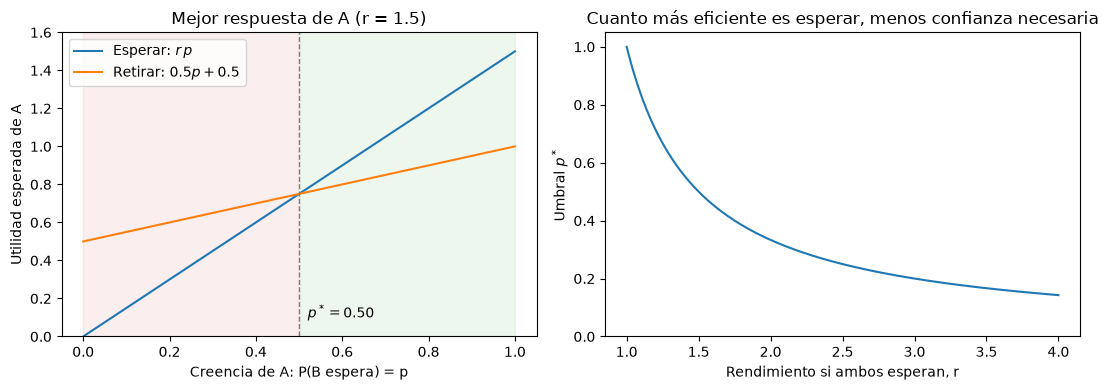

In [10]:
import matplotlib.pyplot as plt
from pathlib import Path

p = np.linspace(0, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Panel izquierdo: utilidades esperadas para r = 1.5
r = 1.5
p_star = umbral_creencia(r)
ax = axes[0]
ax.plot(p, r * p, label="Esperar: $r\\,p$")
ax.plot(p, 0.5 * p + 0.5, label="Retirar: $0.5p + 0.5$")
ax.axvline(p_star, color="gray", ls="--", lw=1)
ax.annotate(f"$p^* = {p_star:.2f}$", (p_star + 0.02, 0.1))
ax.fill_between(p, 0, 1.6, where=p < p_star, color="tab:red", alpha=0.08)
ax.fill_between(p, 0, 1.6, where=p > p_star, color="tab:green", alpha=0.08)
ax.set(xlabel="Creencia de A: P(B espera) = p", ylabel="Utilidad esperada de A",
       title="Mejor respuesta de A (r = 1.5)", ylim=(0, 1.6))
ax.legend(loc="upper left")

# Panel derecho: el umbral en función de r
ax = axes[1]
rs = np.linspace(1.0, 4.0, 200)
ax.plot(rs, umbral_creencia(rs))
ax.set(xlabel="Rendimiento si ambos esperan, r", ylabel="Umbral $p^*$",
       title="Cuanto más eficiente es esperar, menos confianza necesaria", ylim=(0, 1.05))

plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
plt.savefig("../figures/01_umbral_creencia.png", dpi=150)
plt.show()

En el panel izquierdo, la zona roja ($p < p^*$) es donde a A le conviene retirar y la verde ($p > p^*$) donde le conviene esperar. En el derecho se ve que $p^*$ cae rápidamente al aumentar $r$, y vale 1 cuando $r = 1$, justo cuando esperar deja de compensar.

### 6.5 ¿ayuda una reserva de liquidez?

Supongamos que el banco guarda una reserva, de modo que si **ambos retiran** cada uno cobra **0.8** en lugar de 0.5. El resto de pagos no cambia:

$$
\begin{array}{c|cc}
 & \text{B espera} & \text{B retira} \\
\hline
\text{A espera} & (1.5,\ 1.5) & (0,\ 1) \\
\text{A retira} & (1,\ 0) & (0.8,\ 0.8)
\end{array}
$$

**Utilidades esperadas de A** (con $p$ = probabilidad de que B espere):

- Esperar: $\mathbb{E}[U_A(E)] = 1.5p + 0\cdot(1-p) = 1.5p$ (no cambia)
- Retirar: $\mathbb{E}[U_A(R)] = 1\cdot p + 0.8\,(1-p) = 0.2p + 0.8$

**Principio de indiferencia:**

$$1.5p = 0.2p + 0.8 \quad\Longrightarrow\quad 1.3p = 0.8 \quad\Longrightarrow\quad p^* = \frac{0.8}{1.3} \approx 0.615$$

**El umbral sube** (de 0.5 a 0.615): ahora hace falta *más* confianza en el otro para que compense esperar. La reserva ha hecho la corrida **más** fácil.

**¿Por qué?** La reserva protege a **quien retira**: en el peor escenario (ambos retiran) retirar ya no es tan malo, y eso lo hace más atractivo. Pero quien de verdad tiene miedo es **quien espera mientras el otro retira**, y ese sigue cobrando 0.

> **Lección:** para frenar el suceso no basta con añadir liquidez; hay que proteger **a quien se queda**. Esa es la lógica del **seguro de depósitos**.

### 6.6 Fórmula general del umbral

Con una matriz de pagos genérica para A:

$$
\begin{array}{c|cc}
 & \text{B espera} & \text{B retira} \\
\hline
\text{A espera} & r & c \\
\text{A retira} & 1 & d
\end{array}
$$

las utilidades esperadas son $\mathbb{E}[U_A(E)] = rp + c(1-p)$ y $\mathbb{E}[U_A(R)] = p + d(1-p)$. Igualando y despejando:

$$rp + c - cp = p + d - dp \;\Longrightarrow\; p\,\big[(r-1) + (d-c)\big] = d - c$$

$$\boxed{p^* = \frac{d - c}{(r-1) + (d-c)}}$$

**Lectura de cada término:**

- $(r-1)$: lo que se gana por esperar cuando el otro espera, el **beneficio directo de la confianza**.
- $(d-c)$: lo que se gana por retirar cuando el otro retira, el **beneficio directo del miedo**.
- $p^* = \dfrac{\text{miedo}}{\text{confianza} + \text{miedo}}$

Cualquier política anticorrida puede leerse con esta fórmula: o **sube el beneficio de la confianza** o **baja el beneficio del miedo**. Comprobamos tres escenarios:

| Escenario | $r$ | $c$ | $d$ | $p^*$ |
|---|---|---|---|---|
| Original | 1.5 | 0 | 0.5 | 0.5 |
| Reserva que protege a quien retira | 1.5 | 0 | 0.8 | 0.615 |
| Protección a quien espera (tipo seguro de depósitos) | 1.5 | 0.3 | 0.5 | 0.286 |

Verificamos la fórmula contra `nashpy`, como en la sección 6.4.

In [11]:
def matriz_pagos_general(r, c, d):
    # Pagos de A (filas: A espera/retira; columnas: B espera/retira)
    return np.array([[r, c], [1, d]])

def umbral_general(r, c, d):
    # p* = premio del miedo / (premio de la confianza + premio del miedo)
    miedo = d - c
    confianza = r - 1
    return miedo / (confianza + miedo)

escenarios = {
    "Original":                        (1.5, 0.0, 0.5),
    "Reserva (protege al que retira)": (1.5, 0.0, 0.8),
    "Seguro (protege al que espera)":  (1.5, 0.3, 0.5),
}

print(f"{'Escenario':<34} | {'p* fórmula':>10} | {'p* nashpy':>10}")
print("-" * 60)
for nombre, (r, c, d) in escenarios.items():
    A_g = matriz_pagos_general(r, c, d)
    juego = nash.Game(A_g, A_g.T)
    mixto = [eq for eq in juego.support_enumeration() if 0 < eq[1][0] < 1][0]
    print(f"{nombre:<34} | {umbral_general(r, c, d):>10.4f} | {mixto[1][0]:>10.4f}")

Escenario                          | p* fórmula |  p* nashpy
------------------------------------------------------------
Original                           |     0.5000 |     0.5000
Reserva (protege al que retira)    |     0.6154 |     0.6154
Seguro (protege al que espera)     |     0.2857 |     0.2857


Las columnas coinciden. Para ver el contraste de forma continua, dibujamos cómo se mueve $p^*$ cuando aumentamos poco a poco cada tipo de protección:

- **Reserva:** subimos $d$ (lo que cobra quien retira si ambos retiran) de 0.5 a 1.
- **Seguro:** subimos $c$ (lo que cobra quien espera si el otro retira) de 0 a 0.5.

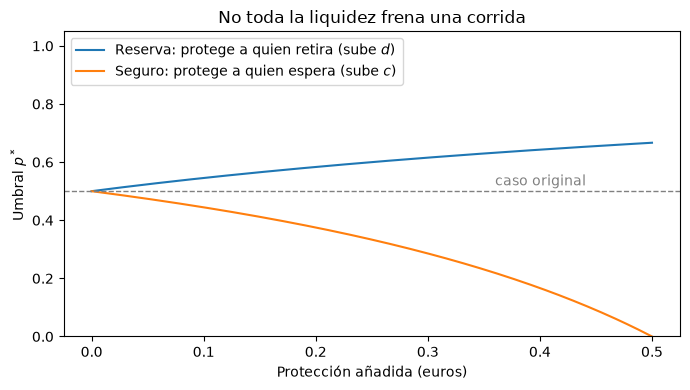

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))

proteccion = np.linspace(0, 0.5, 200)   # cuánto se añade respecto al caso original

# Reserva: d = 0.5 + proteccion, c = 0
ax.plot(proteccion, umbral_general(1.5, 0.0, 0.5 + proteccion),
        label="Reserva: protege a quien retira (sube $d$)")
# Seguro: c = proteccion, d = 0.5
ax.plot(proteccion, umbral_general(1.5, proteccion, 0.5),
        label="Seguro: protege a quien espera (sube $c$)")

ax.axhline(0.5, color="gray", ls="--", lw=1)
ax.annotate("caso original", (0.36, 0.52), color="gray")
ax.set(xlabel="Protección añadida (euros)", ylabel="Umbral $p^*$",
       title="No toda la liquidez frena una corrida", ylim=(0, 1.05))
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("../figures/01_reserva_vs_seguro.png", dpi=150)
plt.show()

**Cómo leer la figura.** Las dos políticas añaden la misma cantidad en el eje horizontal, pero tienen efectos **opuestos**: la reserva que protege a quien retira **sube** el umbral (más fragilidad), mientras que proteger a quien espera lo **baja** hasta 0, punto en el que esperar nunca es peor que retirar y el pánico deja de tener sentido.

Por eso, en marzo de 2023, la medida decisiva con Silicon Valley Bank fue **garantizar todos los depósitos**, y no solo dar liquidez al banco.

## 7. Purificación de Harsanyi: ¿por qué aleatorizar?

### 7.1 El problema

En el apartado 6.1 dejamos abierta una aparente contradicción. Según el principio de indiferencia, en el equilibrio mixto cada depositante está *exactamente* indiferente entre esperar y retirar, y aun así se le atribuye una probabilidad concreta, 0.5, a cada acción. Si los jugadores razonan y deciden en base a cálculos, ¿por qué iban a tirar una moneda?

La respuesta la dio **John Harsanyi (1973)** y es sencilla: **nadie tira ninguna moneda**. La aparente aleatoriedad es, en realidad, **información privada** que los demás no observan. Cada jugador decide de forma completamente determinista según su propia situación, pero como el resto no conoce esa situación, desde fuera su decisión *parece* aleatoria.

### 7.2 El modelo perturbado

Añadimos al modelo un ingrediente muy realista: cada depositante $i$ tiene una pequeña **necesidad de liquidez privada** $\varepsilon_i$ (una factura que pagar, una oportunidad de inversión, cierto nerviosismo...). Formalmente:

- $\varepsilon_i$ se suma al pago de **Retirar**: si $\varepsilon_i > 0$ retirar le resulta algo más atractivo; si $\varepsilon_i < 0$, algo menos.
- $\varepsilon_A$ y $\varepsilon_B$ son independientes y siguen una distribución uniforme $\mathcal{U}[-\eta,\, \eta]$, con $\eta > 0$ pequeño.
- Cada depositante **conoce su propio** $\varepsilon_i$, pero **no** el del otro.

Con $r = 1.5$ y $p$ la creencia de A de que B espera, las utilidades esperadas de A pasan a ser:

$$\mathbb{E}[U_A(E)] = 1.5p \qquad\qquad \mathbb{E}[U_A(R)] = 0.5p + 0.5 + \varepsilon_A$$

A retira si y solo si la segunda es mayor que la primera:

$$0.5p + 0.5 + \varepsilon_A > 1.5p \quad\Longleftrightarrow\quad \varepsilon_A > 0.5 - p$$

Es decir, A sigue una **estrategia de umbral**: observa su $\varepsilon_A$, lo compara con $0.5 - p$ y decide **sin aleatorizar**. Se trata de una estrategia **pura**, aunque dependa de una información que solo él conoce.

### 7.3 El equilibrio

Desde el punto de vista de B, que no conoce $\varepsilon_A$, la decisión de A es una variable aleatoria. La probabilidad de que A espere es

$$F(p) = \mathbb{P}\big(\varepsilon_A < p - 0.5\big) = \frac{(p - 0.5) + \eta}{2\eta}, \qquad \text{acotada al intervalo } [0, 1].$$

La función $F$ responde a la pregunta: *si todos creen que la probabilidad de esperar es $p$, ¿qué fracción espera realmente?*

En un equilibrio las creencias deben ser **coherentes** con lo que efectivamente ocurre, es decir, $F(p) = p$: los equilibrios son los **puntos fijos** de $F$. En la región interior:

$$\frac{p - 0.5 + \eta}{2\eta} = p \quad\Longrightarrow\quad p\,(2\eta - 1) = \eta - 0.5 \quad\Longrightarrow\quad p = 0.5$$

**El resultado es exactamente 0.5, independientemente de $\eta$.** En ese equilibrio, cada depositante espera si $\varepsilon_i < 0$ y retira si $\varepsilon_i > 0$. Como la mitad de los valores de $\varepsilon$ son negativos, la mitad espera: **observado desde fuera es idéntico al equilibrio mixto, pero ningún jugador ha aleatorizado.**

Además, si $\eta < 0.5$, $F(0) = 0$ y $F(1) = 1$, de modo que $p = 0$ (pánico) y $p = 1$ (confianza) siguen siendo equilibrios. El juego perturbado conserva, por tanto, los **tres** equilibrios del juego original.

### 7.4 Verificación por simulación

Comprobamos el resultado de forma numérica. Simulamos una población de $N$ depositantes, cada uno con su $\varepsilon_i$, y para cada creencia $p$ calculamos qué fracción decide esperar aplicando la regla de umbral.

In [ ]:
rng = np.random.default_rng(seed=0)

N = 10_000      # número de depositantes simulados
eta = 0.1       # amplitud de la necesidad de liquidez privada

eps = rng.uniform(-eta, eta, N)

def fraccion_que_espera(p):
    # Cada depositante espera si su necesidad de liquidez es menor que p - 0.5
    return np.mean(eps < p - 0.5)

def F_teorica(p):
    return np.clip((p - 0.5 + eta) / (2 * eta), 0, 1)

for p in [0.45, 0.5, 0.55]:
    print(f"p = {p:.2f}  ->  simulada: {fraccion_que_espera(p):.4f}   teórica: {F_teorica(p):.4f}")

Con la creencia $p = 0.5$ espera, en efecto, aproximadamente la mitad de la población. Sin embargo, basta con que la creencia se desplace ligeramente para que la fracción real cambie mucho más: con $p = 0.55$ espera alrededor del 75 %. Representamos $F(p)$ junto a la diagonal $F(p) = p$; los cortes entre ambas son los equilibrios.

In [ ]:
p_grid = np.linspace(0, 1, 201)
F_sim = np.array([fraccion_que_espera(p) for p in p_grid])

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(p_grid, F_sim, label="$F(p)$ simulada")
ax.plot(p_grid, p_grid, color="gray", ls="--", lw=1, label="$F(p) = p$")
ax.plot([0, 0.5, 1], [0, 0.5, 1], "o", color="black", label="Equilibrios")
ax.set(xlabel="Creencia: probabilidad de que el otro espere, $p$",
       ylabel="Fracción que realmente espera, $F(p)$",
       title=f"Purificación de Harsanyi ($\\eta$ = {eta})")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("../figures/01_purificacion.png", dpi=150)
plt.show()

### 7.5 Inestabilidad del equilibrio mixto

La figura permite ver algo más. En $p = 0.5$ la curva $F$ corta a la diagonal con una pendiente $F'(0.5) = \frac{1}{2\eta} > 1$, mucho más inclinada que la diagonal. Esto implica que el equilibrio mixto es **inestable**: cualquier pequeña desviación de las creencias se amplifica.

Para verlo, supongamos que los depositantes actualizan sus creencias observando lo que ocurrió en la ronda anterior:

$$p_{k+1} = F(p_k)$$

Si partimos ligeramente por encima o por debajo de 0.5, la sucesión se aleja del equilibrio mixto:

In [ ]:
for p0 in [0.48, 0.52]:
    p = p0
    trayectoria = [p]
    for k in range(5):
        p = F_teorica(p)
        trayectoria.append(p)
    print(f"p0 = {p0}:  " + "  ->  ".join(f"{x:.2f}" for x in trayectoria))

Partiendo de $0.52$, la confianza se refuerza a sí misma hasta $p = 1$ (todos esperan). Partiendo de $0.48$, la desconfianza se retroalimenta hasta $p = 0$: **la corrida bancaria**. Una diferencia de cuatro centésimas en las creencias iniciales separa los dos desenlaces.

Esta es la lectura financiera del equilibrio mixto: **no es una predicción de lo que ocurrirá, sino la frontera entre la confianza y el pánico**. En términos dinámicos, $p = 0$ y $p = 1$ son equilibrios **estables** (atractores) y $p = 0.5$ es **inestable** (repulsor).

### 7.6 Conclusión y límite de la purificación

La purificación de Harsanyi resuelve la paradoja del apartado 6.1: los equilibrios mixtos pueden entenderse como el resultado agregado de jugadores que deciden de forma **pura y racional** según su información privada. En el caso bancario es una interpretación especialmente natural, ya que ningún cliente de Silicon Valley Bank tiró una moneda: cada uno actuó según su situación, y desde fuera eso se observó como "una fracción de los clientes retira".

Sin embargo, la purificación **no elimina la multiplicidad de equilibrios**: el juego perturbado sigue teniendo los tres. Seguimos sin poder predecir si habrá o no corrida.

Para ello hay que cambiar el **tipo** de información privada. En lugar de perturbaciones independientes en los pagos de cada jugador, los **juegos globales** (Morris y Shin, 1998) suponen que todos reciben una señal con ruido sobre **un mismo fundamental**, la salud del banco $\theta$:

| | Información privada | ¿Elimina la multiplicidad? |
|---|---|---|
| **Purificación de Harsanyi** | Perturbación independiente en los **pagos** de cada jugador | No: explica el equilibrio mixto |
| **Juegos globales** | Señal con ruido sobre un **fundamental común** $\theta$ | Sí: aparece un umbral único $\theta^*$ |

Este será el punto de partida del **notebook 2**.